In [ ]:
import os

print("Current directory:", os.getcwd())
print("\nFiles in /content:")
print(os.listdir("/content"))

Current directory: /content

Files in /content:
['.config', 'Training_labels_updated.csv', 'ppm_updated.csv', '.ipynb_checkpoints', 'sample_data']


In [ ]:
from pathlib import Path
import pandas as pd
import os

BASE = Path("/content")

train_path = BASE / "Training_labels_updated.csv"
ppm_path = BASE / "ppm_updated.csv"

train = pd.read_csv(train_path)
ppm = pd.read_csv(ppm_path)

print("Training data shape:", train.shape)
print("Training columns:", train.columns.tolist())
display(train.head())

print("\nPPM data shape:", ppm.shape)
print("PPM columns:", ppm.columns.tolist())
display(ppm.head())

Training data shape: (24, 12)
Training columns: ['sample_id', '0.002', '0.0063', '0.02', '0.063', '0.2', '0.63', '2', '6.3', '20', '63', '200']


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,F827,9.4904,19.3892,47.6257,89.5554,99.8965,99.9896,100.0000,100.0000,100.0000,100.0000,100.0
1,G190,5.2076,10.2425,23.7537,50.3113,75.8311,85.7233,90.9898,94.8969,98.5814,100.0000,100.0
2,H030,6.7833,10.9091,19.0599,37.3235,66.8349,96.4965,97.9530,99.5691,100.0000,100.0000,100.0
3,H037,0.9320,6.4500,16.3216,27.8019,34.6629,46.3652,62.7168,79.0523,89.7830,100.0000,100.0
4,H038,1.8218,5.1400,10.6113,18.2778,24.6420,35.0767,47.2345,63.3992,81.0851,95.7127,100.0



PPM data shape: (5, 5)
PPM columns: ['phone', 'camera', 'width', 'height', 'ppm']


,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DRIVE = Path('/content/drive/MyDrive')

for folder_name in [
    'Test_All_Photos',
    'Training-All_Photos_updated'
]:
    matches = list(DRIVE.rglob(folder_name))
    print(f'\n{folder_name}:')
    for path in matches[:10]:
        print(path)


Test_All_Photos:
/content/drive/MyDrive/Colab Notebooks/Test_All_Photos

Training-All_Photos_updated:
/content/drive/MyDrive/Colab Notebooks/Training-All_Photos_updated


In [ ]:
from pathlib import Path

TRAIN_IMG_DIR = Path(
    '/content/drive/MyDrive/Training-All_Photos_updated'
)

TEST_IMG_DIR = Path(
    '/content/drive/MyDrive/Test_All_Photos'
)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

train_images = [
    p for p in TRAIN_IMG_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

test_images = [
    p for p in TEST_IMG_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

print("Training images:", len(train_images))
print("Test images:", len(test_images))

print("\nTraining examples:")
for p in train_images[:10]:
    print(p.name)

print("\nTest examples:")
for p in test_images[:10]:
    print(p.name)

Training images: 0
Test images: 0

Training examples:

Test examples:


In [ ]:
from pathlib import Path

TRAIN_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Training-All_Photos_updated"
)

TEST_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Test_All_Photos"
)

for name, folder in [
    ("TRAINING", TRAIN_IMG_DIR),
    ("TEST", TEST_IMG_DIR)
]:
    print(f"\n===== {name} =====")
    print("Folder exists:", folder.exists())

    if folder.exists():
        items = list(folder.iterdir())
        print("Number of immediate contents:", len(items))

        for item in items[:15]:
            print(
                "DIR " if item.is_dir() else "FILE",
                item.name
            )


===== TRAINING =====
Folder exists: True
Number of immediate contents: 127
FILE Motorola_Edge_F827_01.jpg
FILE Motorola_Edge_F827_02.jpg
FILE Motorola_Edge_G190_01.jpg
FILE Motorola_Edge_G190_02.jpg
FILE Motorola_Edge_H030_01.jpg
FILE Motorola_Edge_H030_03.jpg
FILE Motorola_Edge_H030_02.jpg
FILE Motorola_Edge_H030_04.jpg
FILE Motorola_Edge_H037_01.jpg
FILE Motorola_Edge_H037_02.jpg
FILE Motorola_Edge_H037_03.jpg
FILE Motorola_Edge_H038_01.jpg
FILE Motorola_Edge_H038_02.jpg
FILE Motorola_Edge_H038_03.jpg
FILE Motorola_Edge_H126_01.jpg

===== TEST =====
Folder exists: True
Number of immediate contents: 35
FILE iPhone16_HPC_Kleinkummerfeld 2-2 (4).JPG
FILE iPhone16_HPC_Kleinkummerfeld 2-2 (3).JPG
FILE iPhone16_HPC_Kleinkummerfeld 18-3 (4).JPG
FILE iPhone16_HPC_Kleinkummerfeld 2-2 (2).JPG
FILE iPhone14_HPC_Audorfring (1).JPG
FILE iPhone14_HPC_Audorfring (2).JPG
FILE iPhone14_HPC_Audorfring (3).JPG
FILE iPhone14_HPC_Audorfring (4).JPG
FILE iPhone14_HPC_Audorfring (5).JPG
FILE iPhone14_HPC_

In [ ]:
for name, folder in [
    ("TRAINING", TRAIN_IMG_DIR),
    ("TEST", TEST_IMG_DIR)
]:
    files = [p for p in folder.rglob("*") if p.is_file()]

    print(f"\n{name}: {len(files)} total files")

    for p in files[:15]:
        print(p.name, "|", p.suffix)


TRAINING: 127 total files
Motorola_Edge_F827_01.jpg | .jpg
Motorola_Edge_F827_02.jpg | .jpg
Motorola_Edge_G190_01.jpg | .jpg
Motorola_Edge_G190_02.jpg | .jpg
Motorola_Edge_H030_01.jpg | .jpg
Motorola_Edge_H030_03.jpg | .jpg
Motorola_Edge_H030_02.jpg | .jpg
Motorola_Edge_H030_04.jpg | .jpg
Motorola_Edge_H037_01.jpg | .jpg
Motorola_Edge_H037_02.jpg | .jpg
Motorola_Edge_H037_03.jpg | .jpg
Motorola_Edge_H038_01.jpg | .jpg
Motorola_Edge_H038_02.jpg | .jpg
Motorola_Edge_H038_03.jpg | .jpg
Motorola_Edge_H126_01.jpg | .jpg

TEST: 35 total files
iPhone16_HPC_Kleinkummerfeld 2-2 (4).JPG | .JPG
iPhone16_HPC_Kleinkummerfeld 2-2 (3).JPG | .JPG
iPhone16_HPC_Kleinkummerfeld 18-3 (4).JPG | .JPG
iPhone16_HPC_Kleinkummerfeld 2-2 (2).JPG | .JPG
iPhone14_HPC_Audorfring (1).JPG | .JPG
iPhone14_HPC_Audorfring (2).JPG | .JPG
iPhone14_HPC_Audorfring (3).JPG | .JPG
iPhone14_HPC_Audorfring (4).JPG | .JPG
iPhone14_HPC_Audorfring (5).JPG | .JPG
iPhone14_HPC_Münster_BS6_9,0-10m (1).JPG | .JPG
iPhone14_HPC_Münst

In [ ]:
import pandas as pd
from pathlib import Path
from collections import Counter
import re

BASE = Path("/content")
TRAIN_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Training-All_Photos_updated"
)
TEST_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Test_All_Photos"
)

train = pd.read_csv(BASE / "Training_labels_updated.csv")
ppm = pd.read_csv(BASE / "ppm_updated.csv")

print("Training labels:", train.shape)
print("Label columns:", train.columns.tolist())
display(train.head())

print("\nCamera metadata:", ppm.shape)
print("PPM columns:", ppm.columns.tolist())
display(ppm.head())

def extract_sample_id(filename):
    # Matches IDs such as F827, G190, H030 in training filenames.
    match = re.search(r'(?<![A-Za-z0-9])([A-Z]\d{3})(?!\d)', filename)
    return match.group(1) if match else None

train_images = [
    p for p in TRAIN_IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

image_counts = Counter(
    extract_sample_id(p.name)
    for p in train_images
    if extract_sample_id(p.name) is not None
)

print("\nTraining samples in CSV:", train.iloc[:, 0].nunique())
print("Distinct sample IDs extracted from photos:", len(image_counts))
print("Images matched to IDs:", sum(image_counts.values()))
print("Images without an extracted ID:",
      sum(extract_sample_id(p.name) is None for p in train_images))
print("\nPhoto counts per sample:")
print(dict(sorted(image_counts.items())))

Training labels: (24, 12)
Label columns: ['sample_id', '0.002', '0.0063', '0.02', '0.063', '0.2', '0.63', '2', '6.3', '20', '63', '200']


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,F827,9.4904,19.3892,47.6257,89.5554,99.8965,99.9896,100.0000,100.0000,100.0000,100.0000,100.0
1,G190,5.2076,10.2425,23.7537,50.3113,75.8311,85.7233,90.9898,94.8969,98.5814,100.0000,100.0
2,H030,6.7833,10.9091,19.0599,37.3235,66.8349,96.4965,97.9530,99.5691,100.0000,100.0000,100.0
3,H037,0.9320,6.4500,16.3216,27.8019,34.6629,46.3652,62.7168,79.0523,89.7830,100.0000,100.0
4,H038,1.8218,5.1400,10.6113,18.2778,24.6420,35.0767,47.2345,63.3992,81.0851,95.7127,100.0



Camera metadata: (5, 5)
PPM columns: ['phone', 'camera', 'width', 'height', 'ppm']


,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330



Training samples in CSV: 24
Distinct sample IDs extracted from photos: 24
Images matched to IDs: 127
Images without an extracted ID: 0

Photo counts per sample:
{'F827': 5, 'G190': 5, 'H030': 7, 'H037': 6, 'H038': 8, 'H126': 4, 'H181': 6, 'H183': 7, 'H366': 4, 'H367': 4, 'H368': 5, 'H371': 7, 'H372': 6, 'H374': 3, 'H405': 6, 'H493': 5, 'H516': 4, 'H549': 5, 'H615': 5, 'H616': 5, 'H617': 6, 'H637': 3, 'H666': 4, 'H668': 7}


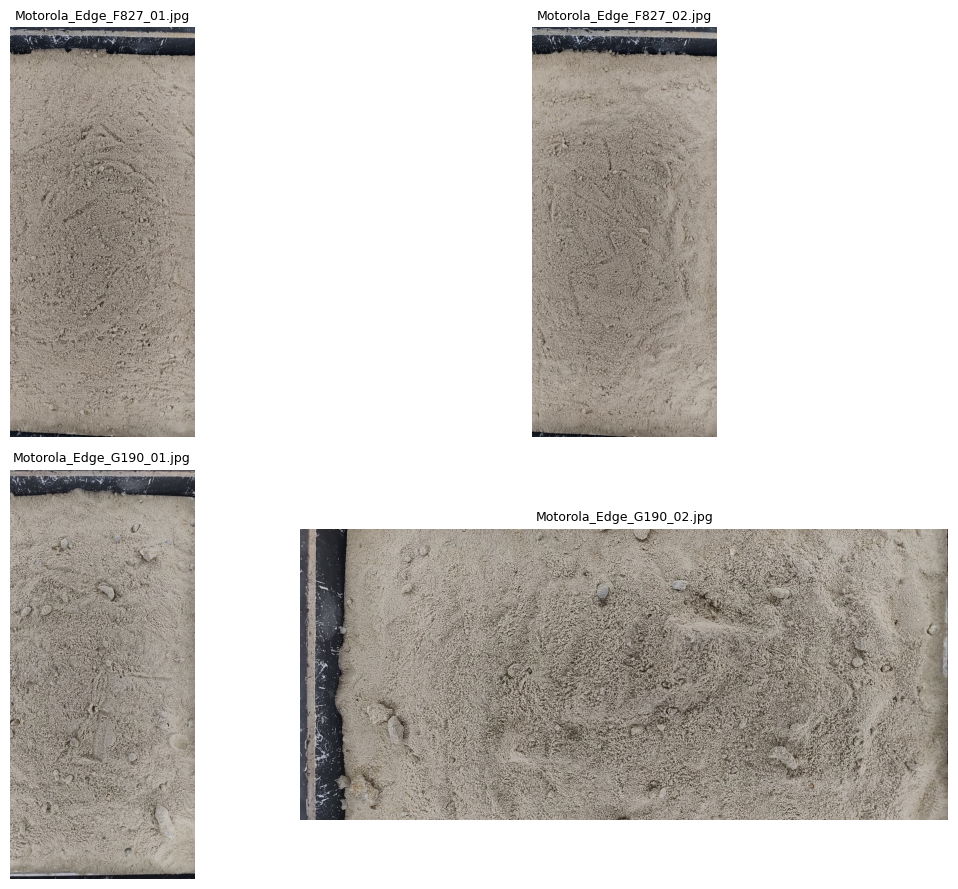

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, path in zip(axes.flat, train_images[:4]):
    with Image.open(path) as img:
        ax.imshow(img)
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

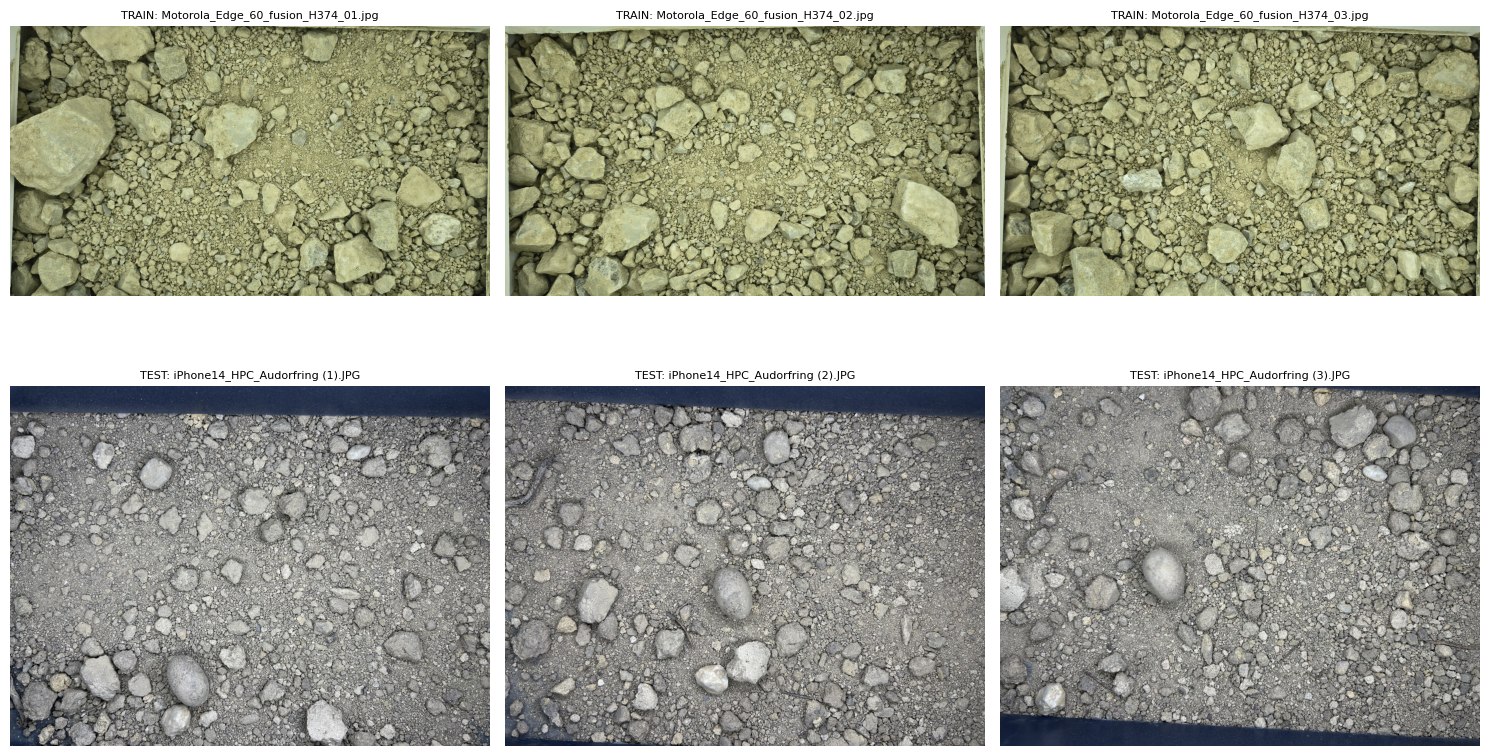

Training photographs: 127
Test photographs: 35

Test filenames:
iPhone14_HPC_Audorfring (1).JPG
iPhone14_HPC_Audorfring (2).JPG
iPhone14_HPC_Audorfring (3).JPG
iPhone14_HPC_Audorfring (4).JPG
iPhone14_HPC_Audorfring (5).JPG
iPhone14_HPC_Münster_BS6_9,0-10m (1).JPG
iPhone14_HPC_Münster_BS6_9,0-10m (2).JPG
iPhone14_HPC_Münster_BS6_9,0-10m (3).JPG
iPhone14_HPC_Münster_BS6_9,0-10m (4).JPG
iPhone14_HPC_Münster_BS6_9,0-10m (5).JPG
iPhone14_HPC_Testfeld Lidl WHV (1).JPG
iPhone14_HPC_Testfeld Lidl WHV (2).JPG
iPhone14_HPC_Testfeld Lidl WHV (3).JPG
iPhone14_HPC_Testfeld Lidl WHV (4).JPG
iPhone16_HPC_Airbus BS10-4bis7 (2).JPG
iPhone16_HPC_Airbus BS10-4bis7 (3).JPG
iPhone16_HPC_Airbus BS12-5bis8 (2).JPG
iPhone16_HPC_Airbus BS12-5bis8 (3).JPG
iPhone16_HPC_Airbus BS12-5bis8 (4).JPG
iPhone16_HPC_Airbus BS6-3 (2).JPG
iPhone16_HPC_Airbus BS6-3 (3).JPG
iPhone16_HPC_Airbus BS6-3 (4).JPG
iPhone16_HPC_Kleinkummerfeld 18-3 (1).JPG
iPhone16_HPC_Kleinkummerfeld 18-3 (2).JPG
iPhone16_HPC_Kleinkummerfeld 

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import re
import pandas as pd

TRAIN_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Training-All_Photos_updated"
)
TEST_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Test_All_Photos"
)

def get_images(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    )

train_images = get_images(TRAIN_IMG_DIR)
test_images = get_images(TEST_IMG_DIR)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, path in zip(axes[0], train_images[:3]):
    with Image.open(path) as img:
        ax.imshow(img.copy())
    ax.set_title("TRAIN: " + path.name, fontsize=8)
    ax.axis("off")

for ax, path in zip(axes[1], test_images[:3]):
    with Image.open(path) as img:
        ax.imshow(img.copy())
    ax.set_title("TEST: " + path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Training photographs:", len(train_images))
print("Test photographs:", len(test_images))
print("\nTest filenames:")
for p in test_images:
    print(p.name)

In [ ]:
from pathlib import Path
import re
import pandas as pd

TRAIN_IMG_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Training-All_Photos_updated"
)

# Extract sample IDs such as F827 and G190 from filenames
image_records = []

for path in TRAIN_IMG_DIR.iterdir():
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        match = re.search(r'(?<![A-Za-z0-9])([A-Z]\d{3})(?!\d)', path.name)

        if match:
            image_records.append({
                "sample_id": match.group(1),
                "filename": path.name
            })

image_df = pd.DataFrame(image_records)

# Count photographs for each sample
photo_counts = (
    image_df.groupby("sample_id")
    .size()
    .reset_index(name="number_of_photos")
    .sort_values("sample_id")
)

# Compare photo IDs with the labeled samples
label_ids = set(train["sample_id"].astype(str))
photo_ids = set(image_df["sample_id"])

print("Labeled samples:", len(label_ids))
print("Samples with matching photographs:", len(label_ids & photo_ids))
print("Photo IDs without labels:", sorted(photo_ids - label_ids))
print("Labels without photographs:", sorted(label_ids - photo_ids))

print("\nPhotographs per sample:")
display(photo_counts)

print("\nNumber of photos per sample:")
display(photo_counts["number_of_photos"].value_counts().sort_index())

Labeled samples: 24
Samples with matching photographs: 24
Photo IDs without labels: []
Labels without photographs: []

Photographs per sample:


,sample_id,number_of_photos
0,F827,5
1,G190,5
2,H030,7
3,H037,6
4,H038,8
5,H126,4
6,H181,6
7,H183,7
8,H366,4
9,H367,4



Number of photos per sample:


,count
number_of_photos,
3,2
4,5
5,7
6,5
7,4
8,1


In [ ]:
import numpy as np
import pandas as pd
import cv2
from pathlib import Path
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict

# Reuse TRAIN_IMG_DIR and image_df from the previous cell

def extract_features(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image.thumbnail((512, 512))
        rgb = np.asarray(image, dtype=np.uint8)

    # Convert RGB to other color representations
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    features = {}

    # Average color and color variation
    for name, array in [("rgb", rgb), ("hsv", hsv)]:
        for i in range(3):
            channel = array[:, :, i].astype(np.float32)
            features[f"{name}_mean_{i}"] = float(channel.mean())
            features[f"{name}_std_{i}"] = float(channel.std())

    # Brightness distribution
    for percentile in [10, 25, 50, 75, 90]:
        features[f"gray_p{percentile}"] = float(
            np.percentile(gray, percentile)
        )

    features["gray_std"] = float(gray.std())

    # Texture: edge density and local intensity changes
    edges = cv2.Canny(gray, 50, 150)
    features["edge_density"] = float((edges > 0).mean())

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    features["laplacian_variance"] = float(laplacian.var())

    # Coarse color histograms
    for channel in range(3):
        hist = cv2.calcHist(
            [rgb], [channel], None, [8], [0, 256]
        ).flatten()
        hist = hist / max(hist.sum(), 1)

        for bin_idx, value in enumerate(hist):
            features[f"rgb_hist_{channel}_{bin_idx}"] = float(value)

    return features


# Extract features for every training photograph
records = []

for _, row in image_df.iterrows():
    path = TRAIN_IMG_DIR / row["filename"]

    try:
        features = extract_features(path)
        features["sample_id"] = row["sample_id"]
        records.append(features)
    except Exception as error:
        print("Could not process:", path.name, error)

photo_features = pd.DataFrame(records)

print("Photographs processed:", len(photo_features))
print("Features per photograph:", photo_features.shape[1] - 1)

# Combine multiple photographs belonging to the same sample.
# The mean gives each sample one feature vector.
sample_features = (
    photo_features.groupby("sample_id")
    .mean(numeric_only=True)
    .sort_index()
)

# Align labels to exactly the same sample order
labels = train.set_index("sample_id")
sample_features = sample_features.loc[
    sample_features.index.intersection(labels.index)
]
labels = labels.loc[sample_features.index]

print("Sample-level feature matrix:", sample_features.shape)
print("Label matrix:", labels.shape)

display(sample_features.head())

Photographs processed: 127
Features per photograph: 44
Sample-level feature matrix: (24, 44)
Label matrix: (24, 11)


,rgb_mean_0,rgb_std_0,rgb_mean_1,rgb_std_1,rgb_mean_2,rgb_std_2,hsv_mean_0,hsv_std_0,hsv_mean_1,hsv_std_1,...,rgb_hist_1_6,rgb_hist_1_7,rgb_hist_2_0,rgb_hist_2_1,rgb_hist_2_2,rgb_hist_2_3,rgb_hist_2_4,rgb_hist_2_5,rgb_hist_2_6,rgb_hist_2_7
sample_id,,,,,,,,,,,,,,,,,,,,,
F827,156.534186,36.215997,145.221548,32.477678,131.049109,28.044419,29.675488,32.044518,46.540704,15.807927,...,0.012235,0.013730,0.003035,0.015981,0.062514,0.321616,0.514037,0.067288,0.002100,0.013429
G190,154.436920,36.608284,147.371017,34.096809,131.259335,30.068191,29.647040,27.412225,41.604271,14.177624,...,0.033475,0.013336,0.002343,0.017087,0.093922,0.292895,0.471889,0.106790,0.002333,0.012741
H030,151.773725,35.782178,141.941622,32.356143,130.472954,28.460511,27.613341,29.851516,41.606528,13.144620,...,0.013392,0.009778,0.003534,0.024685,0.074095,0.300216,0.496202,0.089689,0.001987,0.009592
H037,149.797035,41.235214,142.702649,37.726190,128.017526,32.973428,28.017219,26.342828,42.975699,15.934550,...,0.021597,0.011199,0.004994,0.039309,0.112482,0.268981,0.451591,0.109930,0.002126,0.010586
H038,149.660130,41.876529,145.394999,38.154631,125.880137,32.903283,31.512252,24.303343,47.282345,15.012044,...,0.031135,0.013386,0.003483,0.039233,0.129921,0.296605,0.423665,0.092170,0.002307,0.012616


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_predict

# Grain-size support points, in millimeters
sizes = np.array([
    0.002, 0.0063, 0.02, 0.063, 0.2, 0.63,
    2, 6.3, 20, 63, 200
])

X = sample_features.to_numpy(dtype=float)
# Match the exact column names in your training CSV
target_columns = [
    "0.002", "0.0063", "0.02", "0.063", "0.2", "0.63",
    "2", "6.3", "20", "63", "200"
]

X = sample_features.to_numpy(dtype=float)
Y = labels.loc[sample_features.index, target_columns].to_numpy(dtype=float)

print("Feature matrix:", X.shape)
print("Target matrix:", Y.shape)

# Use log grain size to define the interval weights.
# This is a useful proxy metric; verify it against the competition's
# exact scoring implementation if one is available.
log_sizes = np.log(sizes)

def make_valid(pred):
    """Keep predictions between 0 and 100, monotonic, and ending at 100."""
    pred = np.clip(pred, 0, 100)
    pred = np.maximum.accumulate(pred, axis=1)
    pred[:, -1] = 100.0
    return pred

def log_weighted_curve_error(y_true, y_pred):
    """Normalized area between cumulative curves on log-size axis."""
    y_pred = make_valid(np.asarray(y_pred).copy())
    errors = np.abs(np.asarray(y_true) - y_pred)
    return np.trapz(errors, x=log_sizes, axis=1).mean() / (
        log_sizes[-1] - log_sizes[0]
    )

cv = LeaveOneOut()

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )
}

results = []
oof_predictions = {}

for name, model in models.items():
    # Every sample is predicted without using its own label in training.
    predictions = cross_val_predict(model, X, Y, cv=cv)
    predictions = make_valid(predictions)
    oof_predictions[name] = predictions

    results.append({
        "model": name,
        "log_weighted_curve_error": log_weighted_curve_error(Y, predictions),
        "mean_absolute_error": np.mean(np.abs(Y - predictions))
    })

results_df = pd.DataFrame(results).sort_values("log_weighted_curve_error")
display(results_df)

# Inspect actual vs predicted values for one held-out sample
sample_position = 0
comparison = pd.DataFrame({
    "grain_size_mm": sizes,
    "actual": Y[sample_position],
    "mean_baseline": oof_predictions["Mean baseline"][sample_position],
    "ridge": oof_predictions["Ridge regression"][sample_position]
})

display(comparison.round(2))

Feature matrix: (24, 44)
Target matrix: (24, 11)


/tmp/ipykernel_1252/283351568.py:46: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(errors, x=log_sizes, axis=1).mean() / (
/tmp/ipykernel_1252/283351568.py:46: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(errors, x=log_sizes, axis=1).mean() / (


,model,log_weighted_curve_error,mean_absolute_error
1,Ridge regression,7.632875,7.056626
0,Mean baseline,17.821073,16.343241


,grain_size_mm,actual,mean_baseline,ridge
0,0.00,9.49,2.77,6.40
1,0.01,19.39,5.67,11.75
2,0.02,47.63,13.08,24.26
3,0.06,89.56,27.65,50.84
4,0.20,99.90,43.39,80.50
5,0.63,99.99,53.94,96.27
6,2.00,100.00,63.22,97.93
7,6.30,100.00,78.52,98.02
8,20.00,100.00,93.10,98.67
9,63.00,100.00,99.49,99.85


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut, cross_val_predict

cv = LeaveOneOut()
alphas = [0.1, 1, 10, 100]

def valid_predictions(pred):
    pred = np.clip(pred.copy(), 0, 100)
    pred = np.maximum.accumulate(pred, axis=1)
    pred[:, -1] = 100.0
    return pred

def curve_error(y_true, y_pred):
    pred = valid_predictions(np.asarray(y_pred))
    errors = np.abs(np.asarray(y_true) - pred)
    return np.trapezoid(errors, x=np.log(sizes), axis=1).mean() / (
        np.log(sizes[-1]) - np.log(sizes[0])
    )

alpha_results = []
predictions_by_alpha = {}

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    pred = cross_val_predict(model, X, Y, cv=cv)
    pred = valid_predictions(pred)
    predictions_by_alpha[alpha] = pred

    alpha_results.append({
        "alpha": alpha,
        "curve_error": curve_error(Y, pred),
        "mean_absolute_error": np.mean(np.abs(Y - pred))
    })

alpha_results = pd.DataFrame(alpha_results).sort_values("curve_error")
display(alpha_results.round(3))

# Show how the alpha=10 model performs on each held-out sample
pred = predictions_by_alpha[10]

per_sample = pd.DataFrame({
    "sample_id": sample_features.index,
    "MAE": np.mean(np.abs(Y - pred), axis=1),
    "curve_error": np.trapezoid(
        np.abs(Y - pred), x=np.log(sizes), axis=1
    ) / (np.log(sizes[-1]) - np.log(sizes[0]))
}).sort_values("MAE", ascending=False)

display(per_sample.round(2))

,alpha,curve_error,mean_absolute_error
2,10.0,7.633,7.057
1,1.0,8.243,7.626
3,100.0,8.587,7.918
0,0.1,8.943,8.285


,sample_id,MAE,curve_error
4,H038,15.26,16.61
14,H405,15.06,15.88
5,H126,14.16,15.31
19,H616,13.78,14.83
3,H037,11.32,12.23
23,H668,9.65,10.49
0,F827,9.22,9.99
20,H617,8.04,8.55
16,H516,7.89,8.63
15,H493,7.30,8.03


In [ ]:
import re
import pandas as pd

# Extract the camera/model name from each filename
def get_camera_name(filename):
    match = re.search(
        r'(?<![A-Za-z0-9])([A-Z]\d{3})(?!\d)',
        filename
    )
    if match:
        return filename[:match.start()].rstrip("_- ").replace("_", " ")
    return "UNKNOWN"

camera_df = image_df.copy()
camera_df["camera_name"] = camera_df["filename"].apply(get_camera_name)

print("Training photos by camera:")
display(
    camera_df.groupby("camera_name")
    .agg(
        number_of_photos=("filename", "count"),
        number_of_samples=("sample_id", "nunique")
    )
    .sort_values("number_of_photos", ascending=False)
)

print("\nPPM metadata:")
display(ppm)

print("\nExample filename-to-camera mapping:")
display(camera_df[["filename", "camera_name"]].head(12))

Training photos by camera:


,number_of_photos,number_of_samples
camera_name,,
Motorola Edge,69,22
Samsung A52,55,22
Motorola Edge 60 fusion,3,1



PPM metadata:


,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330



Example filename-to-camera mapping:


,filename,camera_name
0,Motorola_Edge_F827_01.jpg,Motorola Edge
1,Motorola_Edge_F827_02.jpg,Motorola Edge
2,Motorola_Edge_G190_01.jpg,Motorola Edge
3,Motorola_Edge_G190_02.jpg,Motorola Edge
4,Motorola_Edge_H030_01.jpg,Motorola Edge
5,Motorola_Edge_H030_03.jpg,Motorola Edge
6,Motorola_Edge_H030_02.jpg,Motorola Edge
7,Motorola_Edge_H030_04.jpg,Motorola Edge
8,Motorola_Edge_H037_01.jpg,Motorola Edge
9,Motorola_Edge_H037_02.jpg,Motorola Edge


In [ ]:

# Count how many photos of each camera were taken for each soil sample
camera_by_sample = pd.crosstab(
    camera_df["sample_id"],
    camera_df["camera_name"]
)

print("Camera usage for each soil sample:")
display(camera_by_sample)

print("\nNumber of cameras used per sample:")
display(
    (camera_by_sample > 0).sum(axis=1)
    .value_counts()
    .sort_index()
    .rename_axis("number_of_cameras")
    .to_frame("number_of_samples")
)

print("\nCamera counts in the test images:")
import os

test_files = [
    f for f in os.listdir(TEST_IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

test_camera_counts = pd.Series([
    " ".join(f.split("_HPC_")[0].split("_"))
    if "_HPC_" in f else "UNKNOWN"
    for f in test_files
]).value_counts()

display(test_camera_counts.to_frame("number_of_test_photos"))


Camera usage for each soil sample:


camera_name,Motorola Edge,Motorola Edge 60 fusion,Samsung A52
sample_id,,,
F827,2,0,3
G190,2,0,3
H030,4,0,3
H037,3,0,3
H038,3,0,5
H126,3,0,1
H181,4,0,2
H183,4,0,3
H366,4,0,0



Number of cameras used per sample:


,number_of_samples
number_of_cameras,
1,3
2,21



Camera counts in the test images:


,number_of_test_photos
iPhone16,20
iPhone14,14
iPhone 16,1


In [ ]:

# Check the columns first
print("photo_features columns:", photo_features.columns.tolist())
print("image_df columns:", image_df.columns.tolist())

# Join filenames and sample IDs to the photo-level features
photo_camera_df = photo_features.merge(
    image_df[["sample_id", "filename"]],
    on="sample_id",
    how="left"
)

photo_camera_df["camera_name"] = photo_camera_df["filename"].apply(
    get_camera_name
)

# Select numerical image features
feature_columns = [
    col for col in photo_features.columns
    if col != "sample_id"
]

candidate_features = [
    col for col in feature_columns
    if any(term in col.lower() for term in [
        "mean", "std", "brightness", "gray", "laplacian", "edge"
    ])
]

print("\nJoined table shape:", photo_camera_df.shape)
print("\nCandidate features:")
print(candidate_features)

print("\nAverage feature values by camera:")
display(
    photo_camera_df.groupby("camera_name")[candidate_features]
    .mean()
    .T
)



photo_features columns: ['rgb_mean_0', 'rgb_std_0', 'rgb_mean_1', 'rgb_std_1', 'rgb_mean_2', 'rgb_std_2', 'hsv_mean_0', 'hsv_std_0', 'hsv_mean_1', 'hsv_std_1', 'hsv_mean_2', 'hsv_std_2', 'gray_p10', 'gray_p25', 'gray_p50', 'gray_p75', 'gray_p90', 'gray_std', 'edge_density', 'laplacian_variance', 'rgb_hist_0_0', 'rgb_hist_0_1', 'rgb_hist_0_2', 'rgb_hist_0_3', 'rgb_hist_0_4', 'rgb_hist_0_5', 'rgb_hist_0_6', 'rgb_hist_0_7', 'rgb_hist_1_0', 'rgb_hist_1_1', 'rgb_hist_1_2', 'rgb_hist_1_3', 'rgb_hist_1_4', 'rgb_hist_1_5', 'rgb_hist_1_6', 'rgb_hist_1_7', 'rgb_hist_2_0', 'rgb_hist_2_1', 'rgb_hist_2_2', 'rgb_hist_2_3', 'rgb_hist_2_4', 'rgb_hist_2_5', 'rgb_hist_2_6', 'rgb_hist_2_7', 'sample_id']
image_df columns: ['sample_id', 'filename']

Joined table shape: (713, 47)

Candidate features:
['rgb_mean_0', 'rgb_std_0', 'rgb_mean_1', 'rgb_std_1', 'rgb_mean_2', 'rgb_std_2', 'hsv_mean_0', 'hsv_std_0', 'hsv_mean_1', 'hsv_std_1', 'hsv_mean_2', 'hsv_std_2', 'gray_p10', 'gray_p25', 'gray_p50', 'gray_p75',

camera_name,Motorola Edge,Motorola Edge 60 fusion,Samsung A52
rgb_mean_0,145.752412,141.644221,147.128082
rgb_std_0,42.429869,43.379776,41.969175
rgb_mean_1,137.703017,143.879913,139.070113
rgb_std_1,40.279541,44.235686,39.430696
rgb_mean_2,126.664565,105.055593,126.806444
rgb_std_2,37.703554,37.729352,36.394876
hsv_mean_0,27.054831,31.942514,27.736282
hsv_std_0,29.467802,2.431805,29.003133
hsv_mean_1,40.859623,73.040334,42.426849
hsv_std_1,18.710785,16.546255,17.964567


In [ ]:

# Match each photo feature row to one filename
features_match = photo_features.copy()
files_match = image_df[["sample_id", "filename"]].copy()

features_match["photo_number"] = (
    features_match.groupby("sample_id").cumcount()
)
files_match["photo_number"] = (
    files_match.groupby("sample_id").cumcount()
)

photo_camera_df = features_match.merge(
    files_match,
    on=["sample_id", "photo_number"],
    how="left",
    validate="one_to_one"
)

print("Photo feature rows:", len(photo_features))
print("Matched rows:", len(photo_camera_df))
print("Missing filenames:", photo_camera_df["filename"].isna().sum())

photo_camera_df["camera_name"] = photo_camera_df["filename"].apply(
    get_camera_name
)

print("\nPhotos matched by camera:")
display(photo_camera_df["camera_name"].value_counts().to_frame("photos"))

print("\nExample matched rows:")
display(
    photo_camera_df[
        ["sample_id", "photo_number", "filename", "camera_name"]
    ].head(15)
)


Photo feature rows: 127
Matched rows: 127
Missing filenames: 0

Photos matched by camera:


,photos
camera_name,
Motorola Edge,69
Samsung A52,55
Motorola Edge 60 fusion,3



Example matched rows:


,sample_id,photo_number,filename,camera_name
0,F827,0,Motorola_Edge_F827_01.jpg,Motorola Edge
1,F827,1,Motorola_Edge_F827_02.jpg,Motorola Edge
2,G190,0,Motorola_Edge_G190_01.jpg,Motorola Edge
3,G190,1,Motorola_Edge_G190_02.jpg,Motorola Edge
4,H030,0,Motorola_Edge_H030_01.jpg,Motorola Edge
5,H030,1,Motorola_Edge_H030_03.jpg,Motorola Edge
6,H030,2,Motorola_Edge_H030_02.jpg,Motorola Edge
7,H030,3,Motorola_Edge_H030_04.jpg,Motorola Edge
8,H037,0,Motorola_Edge_H037_01.jpg,Motorola Edge
9,H037,1,Motorola_Edge_H037_02.jpg,Motorola Edge


In [ ]:

candidate_features = [
    "rgb_mean_0",
    "rgb_mean_1",
    "rgb_mean_2",
    "hsv_mean_0",
    "hsv_mean_1",
    "hsv_mean_2",
    "gray_p50",
    "gray_std",
    "edge_density",
    "laplacian_variance",
]

print("Average features by camera (127 matched photos):")
display(
    photo_camera_df.groupby("camera_name")[candidate_features]
    .mean()
    .round(2)
    .T
)

print("\nNumber of distinct soil samples represented per camera:")
display(
    photo_camera_df.groupby("camera_name")["sample_id"]
    .nunique()
    .to_frame("number_of_samples")
)


Average features by camera (127 matched photos):


camera_name,Motorola Edge,Motorola Edge 60 fusion,Samsung A52
rgb_mean_0,140.88,141.64,152.96
rgb_mean_1,133.30,143.88,144.36
rgb_mean_2,126.01,105.06,128.22
hsv_mean_0,22.80,31.94,32.73
hsv_mean_1,33.59,73.04,49.99
hsv_mean_2,141.72,143.98,155.27
gray_p50,142.90,146.67,151.65
gray_std,38.02,43.18,42.64
edge_density,0.32,0.33,0.28
laplacian_variance,4824.86,3783.53,2640.61



Number of distinct soil samples represented per camera:


,number_of_samples
camera_name,
Motorola Edge,22
Motorola Edge 60 fusion,1
Samsung A52,22


In [ ]:

import os
import pandas as pd

test_files = sorted([
    f for f in os.listdir(TEST_IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

test_df = pd.DataFrame({"filename": test_files})

def get_test_camera(filename):
    prefix = filename.split("_HPC_")[0] if "_HPC_" in filename else "UNKNOWN"
    return prefix.replace("_", " ")

test_df["camera_name"] = test_df["filename"].apply(get_test_camera)

print("Total test photos:", len(test_df))
print("\nTest photos by camera:")
display(test_df["camera_name"].value_counts().to_frame("number_of_photos"))

print("\nAll test filenames:")
display(test_df)


Total test photos: 35

Test photos by camera:


,number_of_photos
camera_name,
iPhone16,20
iPhone14,14
iPhone 16,1



All test filenames:


,filename,camera_name
0,iPhone14_HPC_Audorfring (1).JPG,iPhone14
1,iPhone14_HPC_Audorfring (2).JPG,iPhone14
2,iPhone14_HPC_Audorfring (3).JPG,iPhone14
3,iPhone14_HPC_Audorfring (4).JPG,iPhone14
4,iPhone14_HPC_Audorfring (5).JPG,iPhone14
5,"iPhone14_HPC_Münster_BS6_9,0-10m (1).JPG",iPhone14
6,"iPhone14_HPC_Münster_BS6_9,0-10m (2).JPG",iPhone14
7,"iPhone14_HPC_Münster_BS6_9,0-10m (3).JPG",iPhone14
8,"iPhone14_HPC_Münster_BS6_9,0-10m (4).JPG",iPhone14
9,"iPhone14_HPC_Münster_BS6_9,0-10m (5).JPG",iPhone14


In [ ]:

import inspect

print("Functions related to image processing:")
for name, obj in list(globals().items()):
    if callable(obj) and (
        "extract" in name.lower()
        or "feature" in name.lower()
        or "image" in name.lower()
    ):
        try:
            print(f"\nFunction: {name}")
            print(inspect.signature(obj))
        except (TypeError, ValueError):
            print(f"\nFunction: {name}")


Functions related to image processing:

Function: extract_sample_id
(filename)

Function: get_images
(folder)

Function: extract_features
(image_path)


In [ ]:

import os
import pandas as pd

test_files = sorted([
    f for f in os.listdir(TEST_IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

test_photo_features = []

for filename in test_files:
    image_path = os.path.join(TEST_IMG_DIR, filename)
    features = extract_features(image_path)

    if features is not None:
        test_photo_features.append({
            "filename": filename,
            **features
        })

test_photo_features = pd.DataFrame(test_photo_features)

print("Test photos found:", len(test_files))
print("Test photos processed:", len(test_photo_features))
print("Feature table shape:", test_photo_features.shape)
print("\nFirst five rows:")
display(test_photo_features.head())


Test photos found: 35
Test photos processed: 35
Feature table shape: (35, 45)

First five rows:


,filename,rgb_mean_0,rgb_std_0,rgb_mean_1,rgb_std_1,rgb_mean_2,rgb_std_2,hsv_mean_0,hsv_std_0,hsv_mean_1,...,rgb_hist_1_6,rgb_hist_1_7,rgb_hist_2_0,rgb_hist_2_1,rgb_hist_2_2,rgb_hist_2_3,rgb_hist_2_4,rgb_hist_2_5,rgb_hist_2_6,rgb_hist_2_7
0,iPhone14_HPC_Audorfring (1).JPG,133.403183,46.582222,134.446243,44.713707,133.764648,39.865944,48.895489,38.084347,17.804327,...,0.085327,0.006378,0.002645,0.028102,0.163930,0.226517,0.300598,0.209727,0.064275,0.004206
1,iPhone14_HPC_Audorfring (2).JPG,132.326950,43.805683,132.074692,42.022671,130.189163,37.417465,41.051121,38.748867,18.341858,...,0.063390,0.006856,0.001770,0.026749,0.168381,0.265381,0.311193,0.179306,0.043340,0.003881
2,iPhone14_HPC_Audorfring (3).JPG,132.785782,43.072453,133.012772,41.624096,130.095840,37.451862,39.761082,31.960703,17.709869,...,0.061824,0.006449,0.001643,0.047312,0.135050,0.262863,0.338460,0.167928,0.043477,0.003265
3,iPhone14_HPC_Audorfring (4).JPG,130.485474,42.943714,130.507202,41.549858,128.188293,37.677315,41.425827,36.406250,16.687204,...,0.057505,0.005514,0.001872,0.047078,0.152176,0.274155,0.320618,0.160309,0.040573,0.003220
4,iPhone14_HPC_Audorfring (5).JPG,132.200272,42.809258,133.546234,41.453293,132.117615,37.397255,50.846008,34.522358,15.306148,...,0.060903,0.006358,0.001918,0.031769,0.146952,0.241425,0.345846,0.181524,0.046855,0.003713


In [ ]:

import os
import re
import pandas as pd

def get_site_name(filename):
    # Remove the camera prefix and keep the site name
    stem = os.path.splitext(filename)[0]

    if "_HPC_" in stem:
        site = stem.split("_HPC_", 1)[1]
    else:
        site = stem

    # Remove photo-number suffixes such as (1), (2), etc.
    site = re.sub(r"\s*\(\d+\)$", "", site).strip()

    return site

test_photo_features["site_name"] = (
    test_photo_features["filename"].apply(get_site_name)
)

print("Photos per site:")
display(
    test_photo_features.groupby("site_name")
    .agg(
        number_of_photos=("filename", "count")
    )
    .sort_index()
)

# Average the 44 image features for each site
feature_columns = [
    col for col in photo_features.columns
    if col != "sample_id"
]

test_site_features = (
    test_photo_features.groupby("site_name")[feature_columns]
    .mean()
)

print("\nNumber of distinct test sites:", len(test_site_features))
print("Test site feature matrix shape:", test_site_features.shape)


Photos per site:


,number_of_photos
site_name,
Airbus BS10-4bis7,3
Airbus BS12-5bis8,3
Airbus BS6-3,3
Audorfring,5
Kleinkummerfeld 18-3,3
Kleinkummerfeld 2-2,3
Kleinkummerfeld 2-3,3
Kleinkummerfeld 9-4,3
"Münster_BS6_9,0-10m",5



Number of distinct test sites: 10
Test site feature matrix shape: (10, 44)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# Ensure test features match the training feature order
X_train_df = sample_features.copy()
X_test_df = test_site_features[feature_columns].copy()

print("Training features:", X_train_df.shape)
print("Test features:", X_test_df.shape)
print("Same feature columns:", list(X_train_df.columns) == list(X_test_df.columns))

# Train the current best model on all 24 labeled samples
final_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

final_model.fit(X_train_df.to_numpy(dtype=float), Y)

# Predict the 11 cumulative grain-size values for each test site
raw_test_predictions = final_model.predict(
    X_test_df.to_numpy(dtype=float)
)

test_predictions = valid_predictions(raw_test_predictions)

prediction_df = pd.DataFrame(
    test_predictions,
    index=test_site_features.index,
    columns=target_columns
)

print("\nPrediction table shape:", prediction_df.shape)
display(prediction_df.round(2))


Training features: (24, 44)
Test features: (10, 44)
Same feature columns: True

Prediction table shape: (10, 11)


,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
site_name,,,,,,,,,,,
Airbus BS10-4bis7,1.39,3.34,12.95,42.07,72.03,80.28,90.14,100.00,100.00,100.00,100.0
Airbus BS12-5bis8,0.19,1.30,8.53,38.45,69.43,75.19,84.39,98.14,100.00,100.00,100.0
Airbus BS6-3,1.67,4.28,15.66,44.92,70.50,76.55,87.15,100.00,100.00,100.00,100.0
Audorfring,2.96,4.10,6.47,8.46,9.58,22.83,49.03,82.98,94.93,97.86,100.0
Kleinkummerfeld 18-3,2.61,3.96,10.99,35.87,63.39,75.33,89.22,100.00,100.00,100.00,100.0
Kleinkummerfeld 2-2,6.57,11.14,25.55,46.88,76.41,100.00,100.00,100.00,100.00,100.00,100.0
Kleinkummerfeld 2-3,6.10,10.24,23.89,45.73,67.54,84.81,98.11,100.00,100.00,100.00,100.0
Kleinkummerfeld 9-4,1.72,3.62,12.48,39.13,68.77,79.32,88.70,100.00,100.00,100.00,100.0
"Münster_BS6_9,0-10m",3.06,6.86,13.91,13.91,13.91,13.91,13.91,22.32,73.26,96.83,100.0


In [ ]:

# Predict each test photo individually
X_test_photos = test_photo_features[feature_columns].to_numpy(dtype=float)

photo_raw_predictions = final_model.predict(X_test_photos)
photo_predictions = valid_predictions(photo_raw_predictions)

photo_prediction_df = pd.DataFrame(
    photo_predictions,
    columns=target_columns
)

photo_prediction_df["site_name"] = test_photo_features["site_name"].to_numpy()

# Measure variation among photos from the same site
site_variability = photo_prediction_df.groupby("site_name")[target_columns].std()

variability_summary = pd.DataFrame({
    "number_of_photos": photo_prediction_df.groupby("site_name").size(),
    "average_prediction_std": site_variability.mean(axis=1),
    "maximum_prediction_std": site_variability.max(axis=1)
}).sort_values("average_prediction_std", ascending=False)

print("Prediction variation across photos of the same site:")
display(variability_summary.round(2))

print("\nOverall average within-site prediction standard deviation:",
      round(site_variability.mean().mean(), 2))


Prediction variation across photos of the same site:


,number_of_photos,average_prediction_std,maximum_prediction_std
site_name,,,
Kleinkummerfeld 9-4,3,4.82,13.36
Audorfring,5,4.81,12.18
"Münster_BS6_9,0-10m",5,3.36,5.39
Airbus BS10-4bis7,3,3.23,9.77
Airbus BS12-5bis8,3,2.60,7.31
Kleinkummerfeld 2-3,3,1.71,4.50
Kleinkummerfeld 18-3,3,1.59,5.14
Testfeld Lidl WHV,4,1.37,7.85
Kleinkummerfeld 2-2,3,1.24,7.03



Overall average within-site prediction standard deviation: 2.55


In [ ]:


from sklearn.model_selection import LeaveOneOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import numpy as np

sample_ids = sample_features.index.to_list()
Y_all = labels.loc[sample_ids, target_columns].to_numpy(dtype=float)

loo = LeaveOneOut()
pred_feature_avg = np.zeros_like(Y_all)
pred_prediction_avg = np.zeros_like(Y_all)

for train_idx, val_idx in loo.split(sample_ids):
    train_ids = [sample_ids[i] for i in train_idx]
    val_id = sample_ids[val_idx[0]]
    val_position = val_idx[0]

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )
    model.fit(
        sample_features.loc[train_ids, feature_columns].to_numpy(dtype=float),
        labels.loc[train_ids, target_columns].to_numpy(dtype=float)
    )

    # Method 1: average features first
    x_avg = sample_features.loc[[val_id], feature_columns].to_numpy(dtype=float)
    pred_feature_avg[val_position] = valid_predictions(
        model.predict(x_avg)
    )[0]

    # Method 2: predict individual photos, then average predictions
    heldout_photos = train_photo_df[train_photo_df["sample_id"] == val_id]
    x_photos = heldout_photos[feature_columns].to_numpy(dtype=float)
    individual_preds = valid_predictions(model.predict(x_photos))

    averaged_curve = individual_preds.mean(axis=0)
    pred_prediction_avg[val_position] = valid_predictions(
        averaged_curve.reshape(1, -1)
    )[0]

print("Feature averaging:")
print("  Curve error:", round(curve_error(Y_all, pred_feature_avg), 3))
print("  MAE:", round(np.mean(np.abs(Y_all - pred_feature_avg)), 3))

print("\nPrediction averaging:")
print("  Curve error:", round(curve_error(Y_all, pred_prediction_avg), 3))
print("  MAE:", round(np.mean(np.abs(Y_all - pred_prediction_avg)), 3))


Feature averaging:
  Curve error: 7.633
  MAE: 7.057

Prediction averaging:
  Curve error: 8.145
  MAE: 7.523


In [ ]:

print("Site names in prediction_df:")
print(prediction_df.index.tolist())

if "site_name" in prediction_df.columns:
    print("\nSite names in the site_name column:")
    print(prediction_df["site_name"].tolist())


Site names in prediction_df:
['Airbus BS10-4bis7', 'Airbus BS12-5bis8', 'Airbus BS6-3', 'Audorfring', 'Kleinkummerfeld 18-3', 'Kleinkummerfeld 2-2', 'Kleinkummerfeld 2-3', 'Kleinkummerfeld 9-4', 'Münster_BS6_9,0-10m', 'Testfeld Lidl WHV']


In [ ]:

import pandas as pd
import numpy as np
import unicodedata
import re

site_mapping = {
    "HPC_Airbus BS6-3": "Airbus BS6-3",
    "HPC_Audorfring": "Audorfring",
    "HPC_Muenster_BS6_9_0-10m": "Münster_BS6_9,0-10m",
    "HPC_Airbus BS10-4bis7": "Airbus BS10-4bis7",
    "HPC_Airbus BS12-5bis8": "Airbus BS12-5bis8",
    "HPC_Kleinkummerfeld 2-2": "Kleinkummerfeld 2-2",
    "HPC_Kleinkummerfeld 2-3": "Kleinkummerfeld 2-3",
    "HPC_Kleinkummerfeld 9-4": "Kleinkummerfeld 9-4",
    "HPC_Kleinkummerfeld 18-3": "Kleinkummerfeld 18-3",
    "HPC_Testfeld Lidl WHV": "Testfeld Lidl WHV"
}

def normalize_name(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(c for c in value if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", value.lower())

pred_lookup = prediction_df.copy()

if "site_name" in pred_lookup.columns:
    pred_lookup = pred_lookup.set_index("site_name")

# Match normalized names, so accents, spaces, commas and underscores
# do not prevent a match.
normalized_index = {}
for name in pred_lookup.index:
    key = normalize_name(name)
    if key in normalized_index:
        raise ValueError(f"Ambiguous normalized site name: {name}")
    normalized_index[key] = name

rows = []

for sample_id, expected_name in site_mapping.items():
    key = normalize_name(expected_name)

    if key not in normalized_index:
        print("Available names:", pred_lookup.index.tolist())
        raise ValueError(f"Could not match site: {expected_name}")

    actual_name = normalized_index[key]
    values = pred_lookup.loc[actual_name, target_columns].to_numpy(dtype=float)

    row = {"sample_id": sample_id}
    row.update(dict(zip(target_columns, values)))
    rows.append(row)

submission = pd.DataFrame(rows, columns=["sample_id"] + target_columns)

assert submission.shape == (10, 12)
assert submission["sample_id"].is_unique
assert np.isfinite(submission[target_columns].to_numpy(dtype=float)).all()
assert (submission[target_columns].to_numpy(dtype=float) >= 0).all()
assert (submission[target_columns].to_numpy(dtype=float) <= 100).all()

submission.to_csv("/content/submission.csv", index=False)

print("Submission created successfully!")
print("Shape:", submission.shape)
display(submission.round(2))


Submission created successfully!
Shape: (10, 12)


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,1.67,4.28,15.66,44.92,70.50,76.55,87.15,100.00,100.00,100.00,100.0
1,HPC_Audorfring,2.96,4.10,6.47,8.46,9.58,22.83,49.03,82.98,94.93,97.86,100.0
2,HPC_Muenster_BS6_9_0-10m,3.06,6.86,13.91,13.91,13.91,13.91,13.91,22.32,73.26,96.83,100.0
3,HPC_Airbus BS10-4bis7,1.39,3.34,12.95,42.07,72.03,80.28,90.14,100.00,100.00,100.00,100.0
4,HPC_Airbus BS12-5bis8,0.19,1.30,8.53,38.45,69.43,75.19,84.39,98.14,100.00,100.00,100.0
5,HPC_Kleinkummerfeld 2-2,6.57,11.14,25.55,46.88,76.41,100.00,100.00,100.00,100.00,100.00,100.0
6,HPC_Kleinkummerfeld 2-3,6.10,10.24,23.89,45.73,67.54,84.81,98.11,100.00,100.00,100.00,100.0
7,HPC_Kleinkummerfeld 9-4,1.72,3.62,12.48,39.13,68.77,79.32,88.70,100.00,100.00,100.00,100.0
8,HPC_Kleinkummerfeld 18-3,2.61,3.96,10.99,35.87,63.39,75.33,89.22,100.00,100.00,100.00,100.0
9,HPC_Testfeld Lidl WHV,0.00,0.00,0.00,0.00,0.00,0.00,9.47,59.83,89.48,96.92,100.0


In [ ]:

# Reload the actual saved file and verify every row and value.
check = pd.read_csv("/content/submission.csv")

print("Shape:", check.shape)
print("Missing values:", check.isna().sum().sum())
print("Duplicate sample IDs:", check["sample_id"].duplicated().sum())
print("\nLast row:")
display(check.tail(1))

assert check.shape == (10, 12)
assert check.isna().sum().sum() == 0
assert check["sample_id"].duplicated().sum() == 0
assert np.all(np.diff(check[target_columns].to_numpy(dtype=float), axis=1) >= -1e-9)
assert np.allclose(check["200"].to_numpy(dtype=float), 100)

print("\nAll submission format checks passed.")


Shape: (10, 12)
Missing values: 0
Duplicate sample IDs: 0

Last row:


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
9,HPC_Testfeld Lidl WHV,0.0,0.0,0.0,0.0,0.0,0.0,9.467609,59.830134,89.479992,96.919889,100.0



All submission format checks passed.


In [ ]:

from google.colab import files
files.download("/content/submission.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>